# Anonymization

Three ways of hiding a face, each replacing the pixels inside the detected box and leaving the rest of the frame alone. They are what the experiment attacks: the question is whether many anonymized frames together still identify the person that no single one of them reveals.

| method | what it does | strength |
| --- | --- | --- |
| `gaussianblur` | blurs the face | kernel = 0.25 x the longer side of the face box |
| `pixelation` | reduces the face to coarse blocks | 8 blocks along each axis |
| `blackbar` | fills the box with black | none to set |

Both strengths are defined **relative to the face**, not in pixels, so a large and a small face are hidden to the same degree. That matters here because the detected box covers between 2% and 67% of a frame.

The two numbers are this project's own choices rather than values taken from a published method. This notebook is what justifies them: it shows what they do to a face, what the neighbouring settings would have done instead, and how much of the face a detector can still find afterwards.

In [1]:
import cv2
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from tqdm.auto import tqdm

from meles.anonymization import ANONYMIZERS, GaussianBlurAnonymizer, PixelationAnonymizer
from meles.detection import default_detector
from meles.paths import repository_root

sns.set_theme(style="whitegrid")

ROOT = repository_root()
DATA = ROOT / "data"
SAMPLE = 400
EXAMPLES = 5
SEED = 0

structure = pd.read_parquet(DATA / "voxceleb2.parquet", columns=["identity", "video", "path"])
sample = structure.sample(SAMPLE, random_state=SEED)


def load(path):
    """A frame and the face detected in it, before anonymization."""
    image = cv2.imread(str(DATA / path))
    return image, default_detector.detect(image)


def show(axis, image, title=None):
    axis.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    axis.set_axis_off()
    if title:
        axis.set_title(title, fontsize=10)


examples = [load(path) for path in sample["path"].head(EXAMPLES)]
print(f"{len(examples)} example frames, {len(sample):,} frames for the measurements")

5 example frames, 400 frames for the measurements


## What each method looks like

The same frames under every method, at the settings the experiment uses.

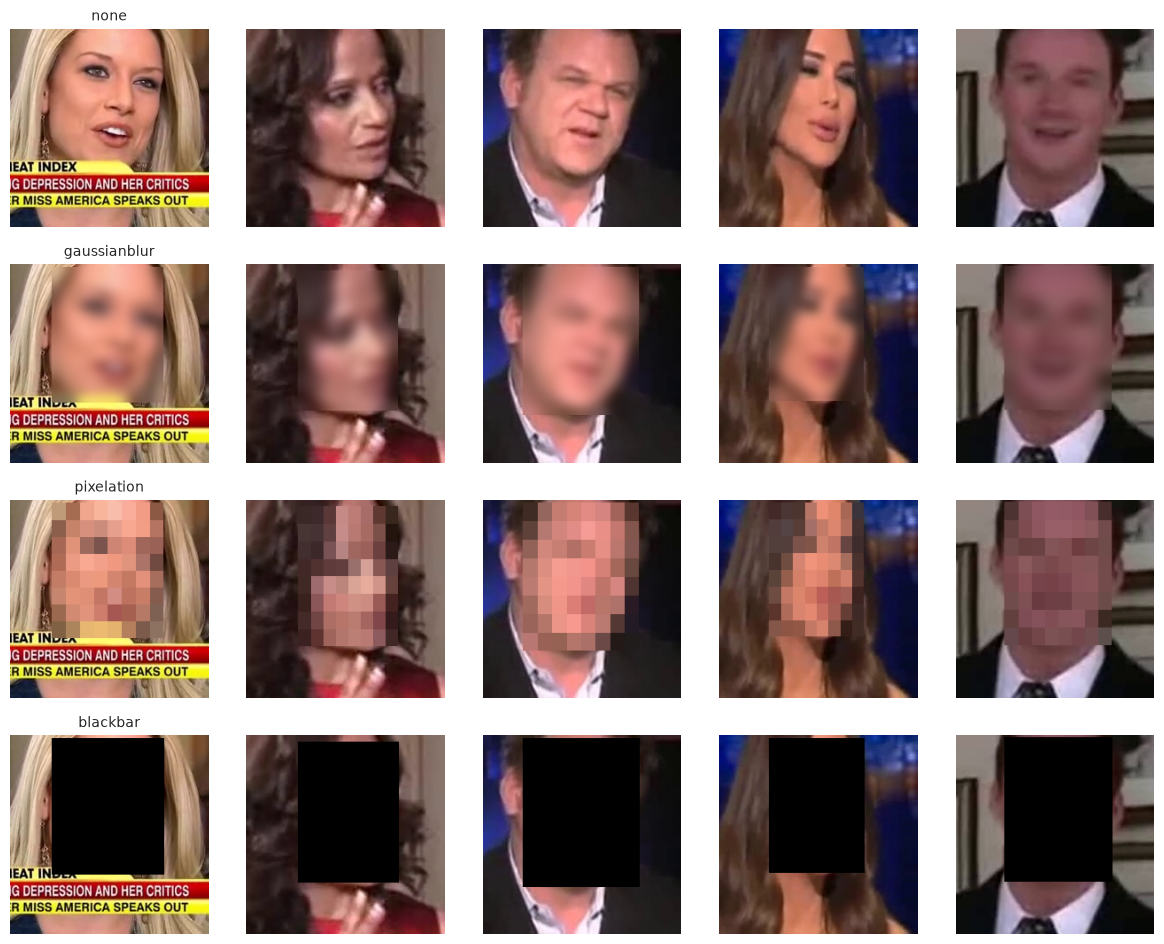

In [2]:
fig, axes = plt.subplots(len(ANONYMIZERS), EXAMPLES, figsize=(2.4 * EXAMPLES, 2.4 * len(ANONYMIZERS)))
for row, (name, anonymizer) in enumerate(ANONYMIZERS.items()):
    for column, (image, area) in enumerate(examples):
        show(axes[row, column], anonymizer.apply(image, area), name if column == 0 else None)
fig.tight_layout()
plt.show()

## What the neighbouring settings would do

Each method is shown across a range of strengths with the chosen setting marked. The useful range is bounded at both ends: too weak and the face is still plainly readable, too strong and the method stops being blur or pixelation and becomes a blank patch, which is what `blackbar` already covers.

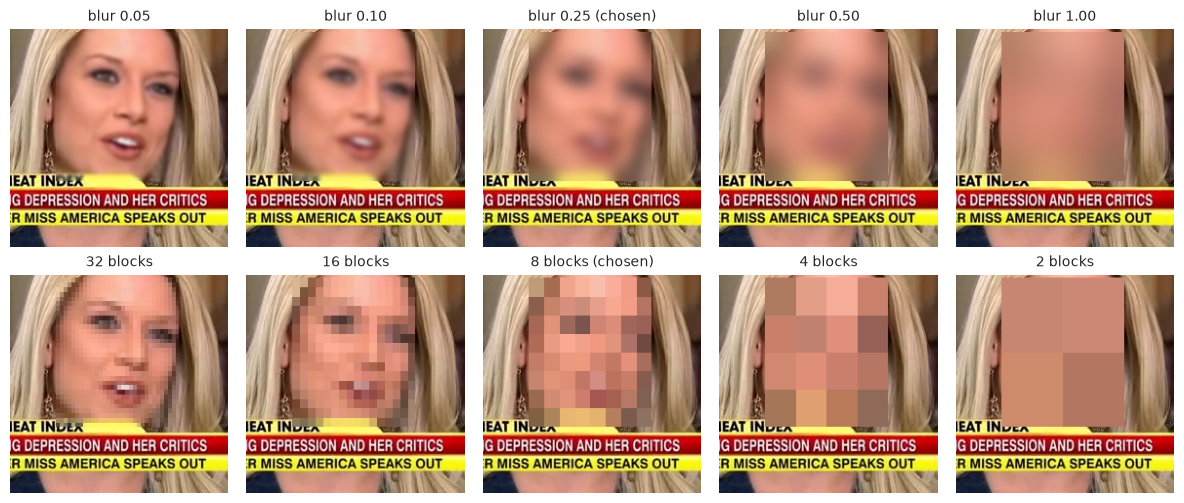

In [3]:
BLUR_STRENGTHS = [0.05, 0.10, 0.25, 0.50, 1.00]
PIXELATION_BLOCKS = [32, 16, 8, 4, 2]

CHOSEN_BLUR = GaussianBlurAnonymizer().strength
CHOSEN_BLOCKS = PixelationAnonymizer().blocks

image, area = examples[0]
fig, axes = plt.subplots(2, len(BLUR_STRENGTHS), figsize=(2.4 * len(BLUR_STRENGTHS), 5.2))

for column, strength in enumerate(BLUR_STRENGTHS):
    chosen = " (chosen)" if strength == CHOSEN_BLUR else ""
    show(axes[0, column], GaussianBlurAnonymizer(strength).apply(image, area), f"blur {strength:.2f}{chosen}")

for column, blocks in enumerate(PIXELATION_BLOCKS):
    chosen = " (chosen)" if blocks == CHOSEN_BLOCKS else ""
    show(axes[1, column], PixelationAnonymizer(blocks).apply(image, area), f"{blocks} blocks{chosen}")

fig.tight_layout()
plt.show()

## How much face is left to find

Every later stage needs to know where the face is, and there are two ways to get it: detect it again on the anonymized frame, or reuse the area found on the clear frame before the anonymization was applied. Running the detector on each method's output and comparing its box against the clear one says whether the first is viable.

Overlap is measured as intersection over union, so 1.0 is the same box and 0.0 is no overlap.


In [4]:
def overlap(first, second):
    """Intersection over union of two face boxes."""
    left, top = max(first.x, second.x), max(first.y, second.y)
    right = min(first.x + first.w, second.x + second.w)
    bottom = min(first.y + first.h, second.y + second.h)
    intersection = max(0, right - left) * max(0, bottom - top)
    return intersection / (first.w * first.h + second.w * second.h - intersection)


rows = []
for path in tqdm(sample["path"], desc="frames"):
    image, clear = load(path)
    for name, anonymizer in ANONYMIZERS.items():
        found = default_detector.detect(anonymizer.apply(image, clear))
        rows.append({"method": name, "score": found.confidence, "overlap": overlap(clear, found)})

survival = pd.DataFrame(rows)
survival.groupby("method").agg(
    score=("score", "mean"),
    overlap=("overlap", "mean"),
    lost=("overlap", lambda column: (column < 0.5).mean()),
).loc[list(ANONYMIZERS)]

frames:   0%|          | 0/400 [00:00<?, ?it/s]

,score,overlap,lost
method,,,
none,0.938323,1.000000,0.0000
gaussianblur,0.891547,0.901774,0.0000
pixelation,0.228651,0.144998,0.9225
blackbar,0.182305,0.061297,1.0000


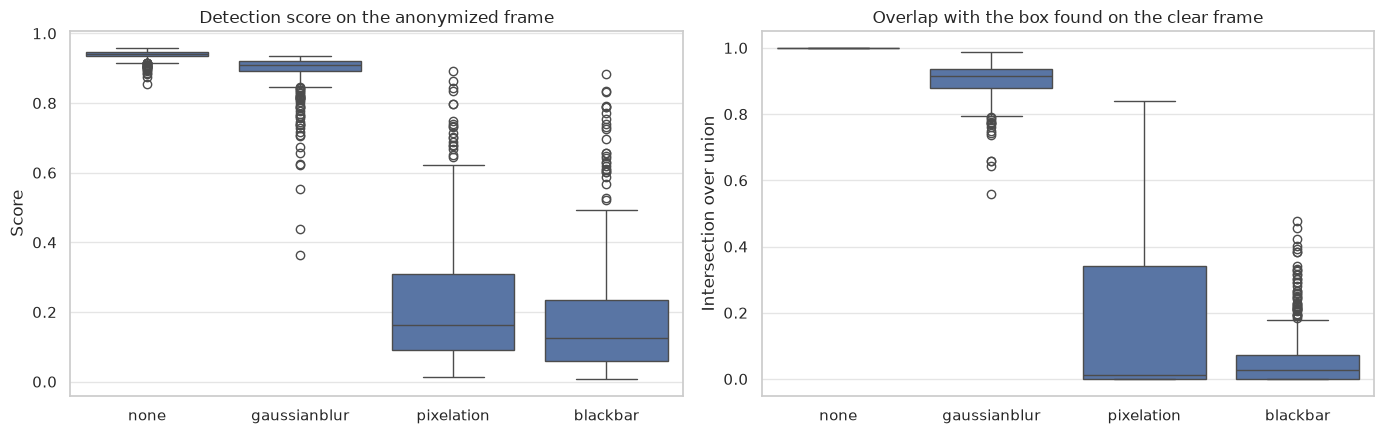

In [5]:
fig, (ax_1, ax_2) = plt.subplots(1, 2, figsize=(14, 4.5))
order = list(ANONYMIZERS)

sns.boxplot(survival, x="method", y="score", order=order, ax=ax_1)
ax_1.set_title("Detection score on the anonymized frame")
ax_1.set_xlabel("")
ax_1.set_ylabel("Score")

sns.boxplot(survival, x="method", y="overlap", order=order, ax=ax_2)
ax_2.set_title("Overlap with the box found on the clear frame")
ax_2.set_xlabel("")
ax_2.set_ylabel("Intersection over union")

fig.tight_layout()
plt.show()

The three methods are not three strengths of one thing. Blur leaves a face the detector still locates almost exactly; pixelation and the black bar leave one it no longer finds, so detecting again on their output returns a box that has slid off the face entirely.

**The experiments therefore locate the face once, on the clear frame, and reuse that area** both to anonymize and to align. Detecting again on the anonymized frame would hand the recognizer a crop that is not on the face for exactly the two methods that matter most, and a low score would then mean "the detector failed" and "the attack failed" indistinguishably. Reusing the clear-frame area also matches how the aggregation model is trained, and describes an attacker who is limited by the anonymization rather than by a detector.

## What the experiment and the model receive

The recognition models do not see a frame. They see one 112x112 crop per frame, warped so that the eyes, nose and mouth sit in a fixed place - and the aggregation model sees several such crops of one identity at once.

The crop is not the anonymized box. It is placed by the landmarks and extends past the box on every side, so part of what both models receive was never anonymized: hair, ears, jawline, neck. That is kept deliberately, because a deployed anonymizer also covers only the face. `blackbar` is what measures it - with the face region zeroed, whatever it still achieves comes from the surroundings alone.


frames:   0%|          | 0/400 [00:00<?, ?it/s]

share of the crop that was anonymized: mean 58.6%, median 58.6%


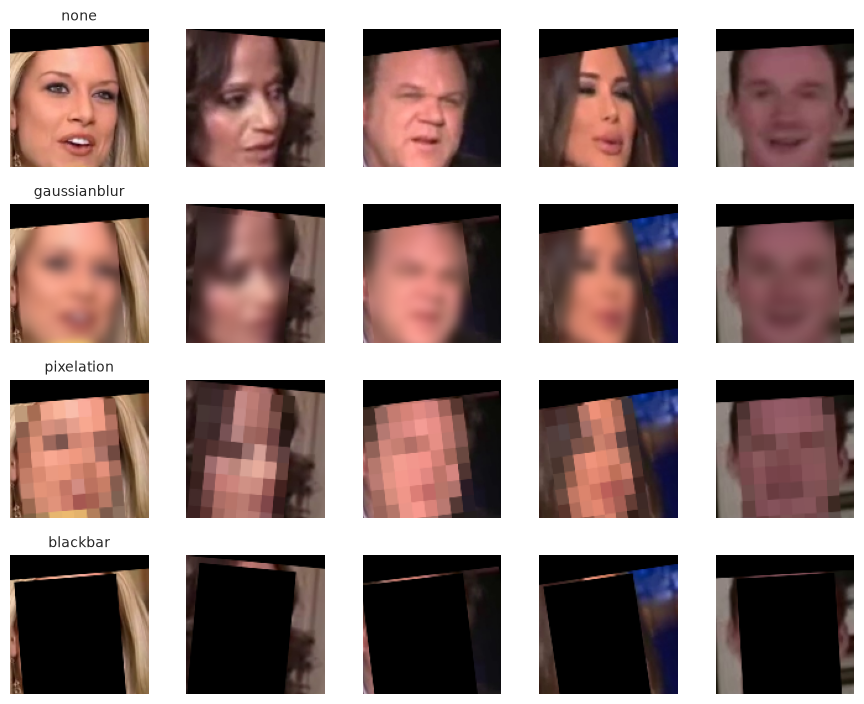

In [6]:
import numpy as np

from meles.alignment import ARCFACE_TEMPLATE, TEMPLATE_SIZE, align_face, umeyama
from meles.anonymization import facial_region


def anonymized_share(image, area):
    """Share of the aligned crop whose pixels came from inside the anonymized box."""
    mask = np.zeros(image.shape[:2], np.uint8)
    x, y, w, h = facial_region(image, area)
    mask[y : y + h, x : x + w] = 255
    warped = cv2.warpAffine(
        mask,
        umeyama(area.landmarks, ARCFACE_TEMPLATE.astype(np.float64)),
        (TEMPLATE_SIZE, TEMPLATE_SIZE),
        flags=cv2.INTER_NEAREST,
    )
    return float((warped > 0).mean())


shares = [anonymized_share(*load(path)) for path in tqdm(sample["path"], desc="frames")]
print(f"share of the crop that was anonymized: mean {np.mean(shares):.1%}, median {np.median(shares):.1%}")

fig, axes = plt.subplots(len(ANONYMIZERS), EXAMPLES, figsize=(1.8 * EXAMPLES, 1.8 * len(ANONYMIZERS)))
for row, (name, anonymizer) in enumerate(ANONYMIZERS.items()):
    for column, (image, area) in enumerate(examples):
        crop = align_face(anonymizer.apply(image, area), area.landmarks)
        show(axes[row, column], crop, name if column == 0 else None)
fig.tight_layout()
plt.show()


One item for the aggregation model is a single identity observed several times. The frames below are drawn from different videos of one person, so they differ in lighting, pose and day - which is the variation the aggregation is meant to exploit, and the reason the number of distinct videos matters more than the number of frames.


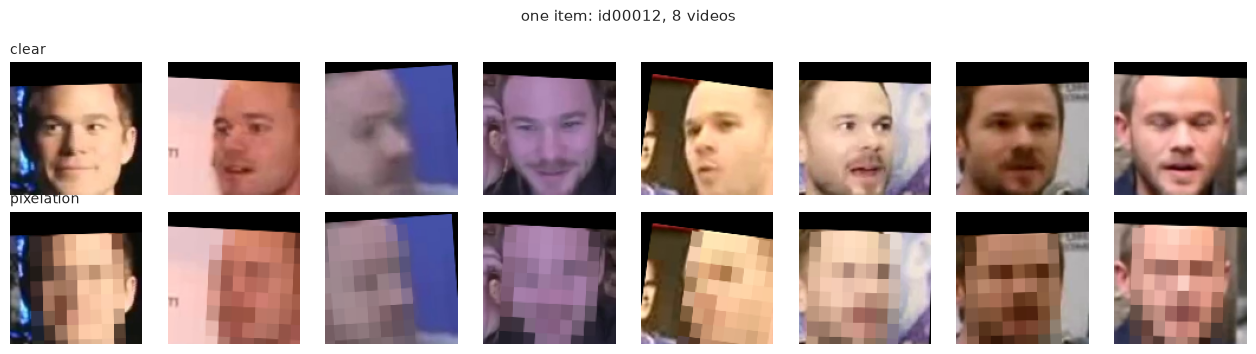

In [7]:
ITEM_FRAMES = 8  # how many observations make up one item
ITEM_METHOD = "pixelation"

# One frame from each of ITEM_FRAMES different videos of a single identity.
videos_per_identity = structure.groupby("identity")["video"].nunique()
identity = videos_per_identity[videos_per_identity >= ITEM_FRAMES].index[0]
item = (
    structure[structure["identity"] == identity]
    .groupby("video", sort=True)
    .head(1)
    .head(ITEM_FRAMES)
)

anonymizer = ANONYMIZERS[ITEM_METHOD]
fig, axes = plt.subplots(2, ITEM_FRAMES, figsize=(1.6 * ITEM_FRAMES, 3.6))
for column, path in enumerate(item["path"]):
    image, area = load(path)
    show(axes[0, column], align_face(image, area.landmarks))
    show(axes[1, column], align_face(anonymizer.apply(image, area), area.landmarks))

axes[0, 0].set_title("clear", loc="left", fontsize=10)
axes[1, 0].set_title(ITEM_METHOD, loc="left", fontsize=10)
fig.suptitle(f"one item: {identity}, {ITEM_FRAMES} videos", fontsize=11)
fig.tight_layout()
plt.show()
